# Ejercicio 1 - Iris con Keras

La idea es correr primero la red original y luego repetir el entrenamiento agregando dos capas. Se mantienen las mismas condiciones para comparar solo el cambio de profundidad.


In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
from sklearn import datasets


In [ ]:
iris = datasets.load_iris()
X = iris.data
y = iris.target
Y = to_categorical(y).astype('uint8')

print(X.shape)
print(Y.shape)


(150, 4)
(150, 3)


## 1. Modelo original 4 x 3 x 3


In [ ]:
modelo_base = keras.Sequential([
    layers.Dense(3, activation='sigmoid', input_shape=(4,), name='capa1'),
    layers.Dense(3, activation='sigmoid', name='salida')
])

modelo_base.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa1 (Dense)                   │ (None, 3)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 3)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27 (108.00 B)

 Trainable params: 27 (108.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo_base.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.03),
    loss=tf.keras.losses.MeanSquaredError()
)

inicio = time.perf_counter()
hist_base = modelo_base.fit(X, Y, epochs=500, verbose=0)
tiempo_base = time.perf_counter() - inicio

pred_base = modelo_base.predict(X, verbose=0)
acc_base = np.mean(np.argmax(pred_base, axis=1) == y)
loss_base = hist_base.history['loss'][-1]

print('Loss final:', round(loss_base, 6))
print('Exactitud:', f'{acc_base*100:.2f}%')
print('Tiempo:', f'{tiempo_base:.3f} s')


Loss final: 0.159195
Exactitud: 66.67%
Tiempo: 17.216 s


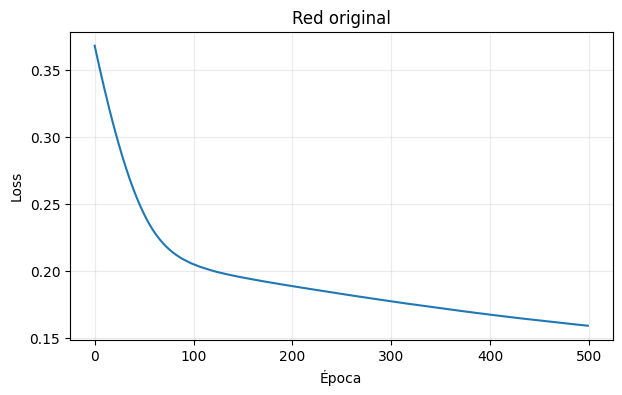

In [ ]:
plt.figure(figsize=(7,4))
plt.plot(hist_base.history['loss'])
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Red original')
plt.grid(alpha=0.25)
plt.show()


## 2. Modelo con dos capas ocultas extra


In [ ]:
modelo_profundo = keras.Sequential([
    layers.Dense(3, activation='sigmoid', input_shape=(4,), name='capa1'),
    layers.Dense(3, activation='sigmoid', name='capa2'),
    layers.Dense(3, activation='sigmoid', name='capa3'),
    layers.Dense(3, activation='sigmoid', name='salida')
])

modelo_profundo.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa1 (Dense)                   │ (None, 3)              │            15 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa2 (Dense)                   │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa3 (Dense)                   │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 3)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51 (204.00 B)

 Trainable params: 51 (204.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo_profundo.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.03),
    loss=tf.keras.losses.MeanSquaredError()
)

inicio = time.perf_counter()
hist_profundo = modelo_profundo.fit(X, Y, epochs=500, verbose=0)
tiempo_profundo = time.perf_counter() - inicio

pred_profundo = modelo_profundo.predict(X, verbose=0)
acc_profundo = np.mean(np.argmax(pred_profundo, axis=1) == y)
loss_profundo = hist_profundo.history['loss'][-1]

print('Loss final:', round(loss_profundo, 6))
print('Exactitud:', f'{acc_profundo*100:.2f}%')
print('Tiempo:', f'{tiempo_profundo:.3f} s')


Loss final: 0.222242
Exactitud: 33.33%
Tiempo: 17.307 s


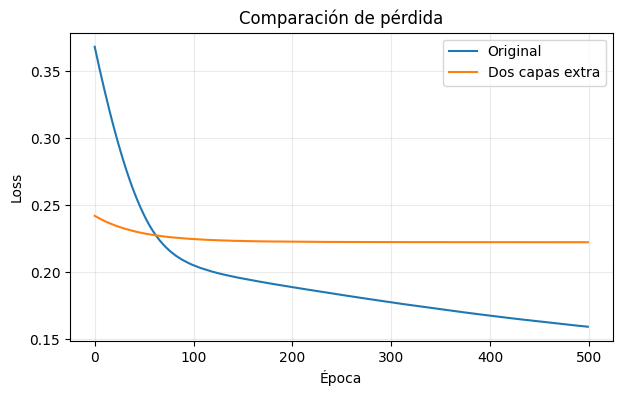


DATOS PARA EL REPORTE
Original: loss=0.159195, exactitud=66.67%, tiempo=17.216s
Profunda: loss=0.222242, exactitud=33.33%, tiempo=17.307s


In [ ]:
plt.figure(figsize=(7,4))
plt.plot(hist_base.history['loss'], label='Original')
plt.plot(hist_profundo.history['loss'], label='Dos capas extra')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Comparación de pérdida')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print('\nDATOS PARA EL REPORTE')
print(f'Original: loss={loss_base:.6f}, exactitud={acc_base*100:.2f}%, tiempo={tiempo_base:.3f}s')
print(f'Profunda: loss={loss_profundo:.6f}, exactitud={acc_profundo*100:.2f}%, tiempo={tiempo_profundo:.3f}s')